<a href="https://colab.research.google.com/github/maitrey21/diabetes_prediction/blob/main/ECEI_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import the necessary Libraries

In [ ]:
import pandas as pd #This library is primarily used for data manipulation and analysis. It provides powerful and flexible data structures designed to handle tabular data
import numpy as np #numpy is a python library used for mathematical computations
from sklearn.model_selection import train_test_split, GridSearchCV #Import a function that allows us to split the data into train and test sets. GridSearchCV: A powerful tool that systematically tests different hyperparameter combinations and finds the best one.
from sklearn.preprocessing import StandardScaler #StandardScaler is used to to standardize or normalize the dataset so that the model does not provide higher weights to features having a higher scale, thereby skewing the results.
from sklearn.metrics import accuracy_score, classification_report #Import the necessary metrics
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier #Load the different models
from imblearn.over_sampling import SMOTE #Used for handling imbalanced datasets. It is a method to balance classes by generating synthetic samples of the minority class rather than just duplicating them.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
import joblib

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving diabetes.csv to diabetes.csv


Create a dataframe & read the dataset

In [ ]:
df = pd.read_csv("diabetes.csv") #DataFrame - Primary data structute in pandas, representing data in a tabular format with rows and columns.  It can store heterogeneous data types within different columns.
print(df.head()) #df.head() - The primary purpose of df.head() is to provide an overview of the data within a data frame. It is a method called on a dataframe. When used without any arguments, it returns the first 5 rows of the data frame by default.
print(df.info()) #Provdies a summary of the dataframe. A list of all columns, their respective data types (dtypes), and the count of non-null values for each column. This is particularly useful for identifying missing data. An estimate of the memory consumed by the DataFrame is also provided.
print(df.describe()) #df.describe - is used to generate descriptive statistics of the dataframe. It analyzes only numeric columns

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768

Handling Missing Values


In [ ]:
def handle_missing_values(df):
    df = df.copy()
    zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI'] #Vital parameters that should ideally not be zero
    df[zero_cols] = df[zero_cols].replace(0, np.nan) #Replace these data samples with Nan

    for col in zero_cols:
        median_0 = df[df['Outcome'] == 0][col].median() #median_0 → Median of the column for patients without diabetes (Outcome == 0).
        median_1 = df[df['Outcome'] == 1][col].median() #median_1 → Median of the column for patients with diabetes (Outcome == 1)
        df.loc[(df['Outcome'] == 0) & (df[col].isna()), col] = median_0 #If Outcome == 0 and column is NaN → replace with median_0.
        df.loc[(df['Outcome'] == 1) & (df[col].isna()), col] = median_1 #If Outcome == 1 and column is NaN → replace with median_1
    return df

df = handle_missing_values(df)


Feature Engineering

In [ ]:
def create_advanced_features(df): #Create advanced features for better model performance and learning
    df = df.copy()
    df['Glucose_BMI'] = df['Glucose'] * df['BMI']
    df['Age_Preg'] = df['Age'] * df['Pregnancies']
    df['Glucose_Insulin'] = df['Glucose'] * df['Insulin']
    df['BMI_squared'] = df['BMI'] ** 2
    df['Age_squared'] = df['Age'] ** 2
    df['Glucose_Age'] = df['Glucose'] / (df['Age'] + 1)
    df['BMI_Age'] = df['BMI'] / (df['Age'] + 1)
    df['Insulin_Glucose'] = df['Insulin'] / (df['Glucose'] + 1)
    df['BP_Category'] = pd.cut(df['BloodPressure'], bins=[0, 80, 90, 120, 200],
                               labels=[0, 1, 2, 3]).astype(int)
    df['BMI_Category'] = pd.cut(df['BMI'], bins=[0, 18.5, 25, 30, 70],
                                labels=[0, 1, 2, 3]).astype(int)
    df['Age_Group'] = pd.cut(df['Age'], bins=[0, 30, 40, 50, 100],
                             labels=[0, 1, 2, 3]).astype(int)
    df['High_Risk_Pregnancy'] = ((df['Pregnancies'] > 5) & (df['Age'] > 30)).astype(int)
    df['Metabolic_Risk'] = ((df['BMI'] > 30) & (df['BloodPressure'] > 85)
                             & (df['Glucose'] > 120)).astype(int)
    return df

df = create_advanced_features(df)


Split the dataset into Training and Test Sets

In [ ]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split( #Split the dataset into train and test sets. 80% - training data and 20% - testing data
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler() #Standardize or normalize the data
X_train = scaler.fit_transform(X_train) #Apply standardization to the training data
X_test = scaler.transform(X_test) #Apply the same standardization to the test data as well

# Convert scaled arrays back to DataFrames to preserve feature names
X_train = pd.DataFrame(X_train, columns=X.columns)
X_test = pd.DataFrame(X_test, columns=X.columns)


smote = SMOTE(random_state=42) #For handling imbalanced datasets
X_train, y_train = smote.fit_resample(X_train, y_train)

Basic model Implementation using Logistic Regression, Random Forest Classifier Support Vector Machines.

In [ ]:
# Import necessary libraries
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# 1. Logistic Regression
# Create a Logistic Regression model
# max_iter=1000 ensures the algorithm runs enough iterations to converge
# random_state=42 ensures results are reproducible
log_reg = LogisticRegression(max_iter=1000, random_state=42)
# Train (fit) the model using training data
log_reg.fit(X_train, y_train)

# Predict the labels (0 = Non-Diabetic, 1 = Diabetic) on test data
y_pred_log = log_reg.predict(X_test)

#  Evaluate the Logistic Regression Model
print(" Logistic Regression Results ")
# Accuracy: percentage of correctly predicted cases
print("Accuracy:", accuracy_score(y_test, y_pred_log))
# Accuracy in Percentage
y_pred_lr = log_reg.predict(X_test)
accuracy_lr = accuracy_score(y_test, y_pred_lr) * 100
print(f"Logistic Regression Accuracy: {accuracy_lr:.2f}%")
# Confusion Matrix: shows True Positives, True Negatives, False Positives, False Negatives
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_log))
# Classification Report: includes Precision, Recall, F1-Score for both classes
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))


 Logistic Regression Results 
Accuracy: 0.7792207792207793
Logistic Regression Accuracy: 77.92%

Confusion Matrix:
 [[73 27]
 [ 7 47]]

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.73      0.81       100
           1       0.64      0.87      0.73        54

    accuracy                           0.78       154
   macro avg       0.77      0.80      0.77       154
weighted avg       0.82      0.78      0.78       154



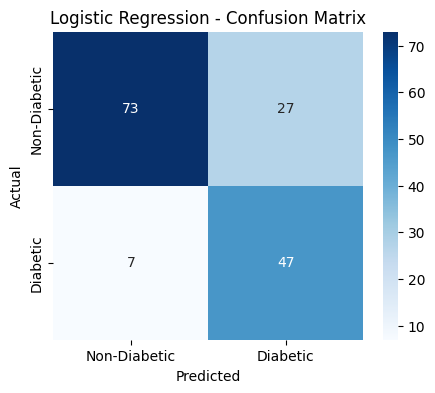

In [ ]:
# Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_log), annot=True, fmt='d', cmap="Blues", xticklabels=['Non-Diabetic','Diabetic'], yticklabels=['Non-Diabetic','Diabetic'])
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:
# 2. Random Forest Classifier
# Create a Random Forest model with 100 decision trees
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
# Train (fit) the model using training data
rf_clf.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_clf.predict(X_test)

# Evaluate the Random Forest Model
print(" Random Forest Results ")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
# Accuracy in Percentage
y_pred_rf = rf_clf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf) * 100
print(f"Random Forest Accuracy: {accuracy_rf:.2f}%")

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))


 Random Forest Results 
Accuracy: 0.8766233766233766
Random Forest Accuracy: 87.66%

Confusion Matrix:
 [[91  9]
 [10 44]]

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.91      0.91       100
           1       0.83      0.81      0.82        54

    accuracy                           0.88       154
   macro avg       0.87      0.86      0.86       154
weighted avg       0.88      0.88      0.88       154



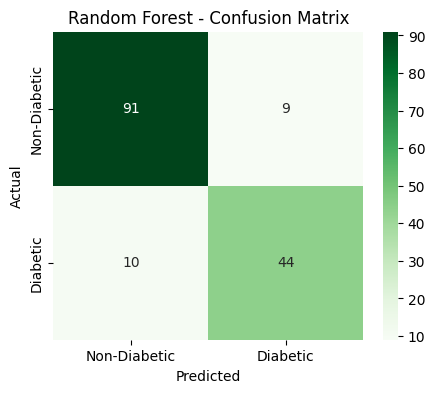

In [ ]:
# Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap="Greens", xticklabels=['Non-Diabetic','Diabetic'], yticklabels=['Non-Diabetic','Diabetic'])
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:
# Sample Predictions
# Take first 5 test samples to compare predictions
sample_input = X_test[:5]  # first 5 samples
print("\nSample Predictions (First 5 Test Cases):")
# Actual values from dataset
print("Actual Labels   :", y_test[:5].values)
# Predictions from Logistic Regression
print("LogReg Predicted:", log_reg.predict(sample_input))
# Predictions from Random Forest
print("RF Predicted    :", rf_clf.predict(sample_input))


Sample Predictions (First 5 Test Cases):
Actual Labels   : [0 0 0 1 0]
LogReg Predicted: [1 0 1 1 0]
RF Predicted    : [0 0 0 1 0]


In [ ]:
# 3. Support Vector Machine (SVM) Model

from sklearn.svm import SVC

# Create SVM model
# kernel='rbf' (Radial Basis Function) is commonly used and works well for non-linear data
# probability=True allows us to get probability estimates later if needed
svm_clf = SVC(kernel='rbf', probability=True, random_state=42)
# Train (fit) the model using training data
svm_clf.fit(X_train, y_train)

# Predict the labels on test data
y_pred_svm = svm_clf.predict(X_test)

# --- Evaluate the SVM Model ---
print(" Support Vector Machine (SVM) Results ")
# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
# Accuracy in percentage
y_pred_svm = svm_clf.predict(X_test)
accuracy_svm = accuracy_score(y_test, y_pred_svm) * 100
print(f"SVM Accuracy: {accuracy_svm:.2f}%")
# Confusion Matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))
# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))

 Support Vector Machine (SVM) Results 
Accuracy: 0.8181818181818182
SVM Accuracy: 81.82%

Confusion Matrix:
 [[78 22]
 [ 6 48]]

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.78      0.85       100
           1       0.69      0.89      0.77        54

    accuracy                           0.82       154
   macro avg       0.81      0.83      0.81       154
weighted avg       0.84      0.82      0.82       154



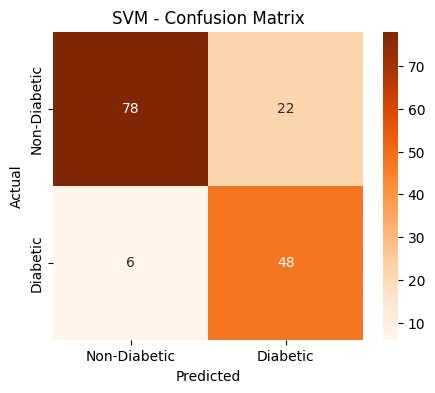

In [ ]:
# Visualize the Confusion Matrix as a heatmap
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_svm),
            annot=True, fmt='d', cmap="Oranges",
            xticklabels=['Non-Diabetic','Diabetic'],
            yticklabels=['Non-Diabetic','Diabetic'])
plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
#  Sample Predictions for Comparison (including SVM)
sample_input = X_test[:5]

print("\nSample Predictions (First 5 Test Cases):")
print("Actual Labels   :", y_test[:5].values)
print("LogReg Predicted:", log_reg.predict(sample_input))
print("RF Predicted    :", rf_clf.predict(sample_input))
print("SVM Predicted   :", svm_clf.predict(sample_input))


Sample Predictions (First 5 Test Cases):
Actual Labels   : [0 0 0 1 0]
LogReg Predicted: [1 0 1 1 0]
RF Predicted    : [0 0 0 1 0]
SVM Predicted   : [0 0 1 1 0]


Hyperparameter Tuning for Logistic Regression

In [ ]:
#In machine learning, a hyperparameter is a configuration variable set by a data scientist before the training process begins, which controls how the model learns from data.
#When a model learns from data, it tries to minimize the loss (error). Sometimes, it learns too well, memorizing noise — this is overfitting. To prevent that, we add a penalty to the loss function that discourages the model from having large weights. Regularization = a penalty added to the model’s loss function to keep it simple.
#With L1 regularization:
#It penalizes large weights.
#Less important features’ weights shrink toward 0.
#The model becomes simpler, interpretable, and less likely to overfit.
#L2, on the other hand, means you just pack smaller versions of everything — you keep all items but compress them to fit better.

from sklearn.model_selection import GridSearchCV #GridSearchCV: A powerful tool that systematically tests different hyperparameter combinations and finds the best one.
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
#accuracy_score: Calculates the proportion of correct predictions.
#classification_report: Gives detailed metrics — precision, recall, F1-score.
#confusion_matrix: Shows how many samples were correctly and incorrectly classified.

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'penalty': ['l2']
} #This tells GridSearchCV which parameteer combinations to try. #Inverse of regularization strength — smaller C = stronger regularization. Controls overfitting.
#Solver: Optimization algorithm used to fit the model.
#penalty: Type of regularization (L1 = Lasso, L2 = Ridge). Helps prevent overfitting.

#Initialize GridSearchCV
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42), #Logistic Regression is the model that we want to tune. max_iter = 1000 allow enough iterations for convergence. (In machine learning, convergence is the process by which a model, through iterative training, reaches a stable state where further learning provides little to no improvement in performance.
    #This stability is reached when the model's error or "loss function" settles within a small, acceptable range, indicating it has effectively learned the underlying patterns in the data. Convergence is often monitored to determine when to stop training, as continued learning would yield diminishing returns.)
    #Many machine learning functions in scikit-learn involve randomness. Because randomness is involved, your results can slightly change every time you run the code. random_state is simply a seed number that controls that randomness — it ensures you get the same random results every time. Instead of 42 any other integer can also be used, but it needs to be constant throughout the code.
    param_grid_lr, #We call the different parameter combinations defined above
    cv=5, #Uses 5-fold cross-validation — your training data is split into 5 parts, the model trains on 4 and validates on 1, rotating 5 times. This gives a reliable estimate of performance.
    scoring='accuracy', #The performance metric GridSearch will optimize for.
    n_jobs=-1 #Uses all available CPU cores for faster computation.
)

#Fit (train) the grid search
grid_lr.fit(X_train, y_train) #This starts the actual tuning process:
#It trains 20 (5x2x2) versions of Logistic Regression (each with different parameters)
#Evaluates each version using 5-fold CV
#Finds which combination performs best
#GridSearchCV tries every possible combination of the parameters specified in the grid
#for each value of C:
    #for each solver:
        #for each penalty:
            #train + evaluate model
#Total combinations=5×2×2=20
#solver='liblinear' supports both 'l1' and 'l2'
#solver='saga' supports both 'l1' and 'l2'
#So in this case, all combinations are valid. (But in some models, certain solvers don’t support some penalties — then GridSearch would skip those invalid ones.)
#GridSearch will do 5-fold cross-validation.
#Each model tested 5 times -  20 × 5 = 100 fits
#After testing all 20 combinations (each evaluated 5 times),
#GridSearchCV:
#Calculates the average cross-validation accuracy for each combination.
#Picks the one with the highest mean accuracy.
#Returns that as your best_estimator_.

#Get the best model and results
best_lr = grid_lr.best_estimator_ #grid_lr.best_estimator_: returns the Logistic Regression model with the best parameters found.
print("\n Best Logistic Regression Params:", grid_lr.best_params_) #grid_lr.best_params_: shows the exact hyperparameter values that gave the best accuracy.
print("Best Cross-Validation Accuracy:", grid_lr.best_score_) #grid_lr.best_score_: shows the average accuracy from 5-fold cross-validation using those best parameters.

#Evaluate the best model on Test/Unseen Data
y_pred_lr = best_lr.predict(X_test) #.predict(X_test) → gets model predictions.
acc_lr = accuracy_score(y_test, y_pred_lr) #Accuracy is calculated
print("\nLogistic Regression Test Accuracy:", acc_lr)
print(classification_report(y_test, y_pred_lr)) #classification_report() → shows:
#Precision: Out of predicted positives, how many are actually positive.
#Recall: Out of actual positives, how many were correctly predicted.
#F1-score: Harmonic mean of precision & recall — useful for imbalanced datasets.



 Best Logistic Regression Params: {'C': 100, 'penalty': 'l2', 'solver': 'liblinear'}
Best Cross-Validation Accuracy: 0.8237500000000001

Logistic Regression Test Accuracy: 0.7597402597402597
              precision    recall  f1-score   support

           0       0.89      0.72      0.80       100
           1       0.62      0.83      0.71        54

    accuracy                           0.76       154
   macro avg       0.75      0.78      0.75       154
weighted avg       0.79      0.76      0.77       154



Hyperparameter Tuning for Random Forest

In [ ]:
import time
start = time.time()
# your model training code here
print("Time taken:", time.time() - start)



from sklearn.model_selection import GridSearchCV #GridSearchCV: A powerful tool that systematically tests different hyperparameter combinations and finds the best one.
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
param_grid_rf = {
    'n_estimators': [100, 200, 500, 800],
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}
 #This defines all the hyperparameters you want GridSearchCV to test, basically the combinations of parameters to try to get the highest accuracy. n_estimators: Number of trees in the forest. More trees usually improve accuracy, but make training slower.
#max_depth: Maximum depth of each tree. Controls how complex each tree is. None means grow trees fully (can overfit)
#min_samples_split: Minimum number of samples required to split an internal node. Higher values = fewer splits = simpler model
#min_samples_leaf: Minimum number of samples at a leaf node. Prevents small, specific leaf nodes (reduces overfitting)
#total combinations =
#3 (n_estimators) × 4 (max_depth) × 3 (min_samples_split) × 3 (min_samples_leaf)
# = 108 different Random Forest models
#cv=5, that means 108 × 5 = 540 fits

#Initialize GridSearchCV
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42), #The model that we train
    param_grid_rf, #Call the parameter combinations defined above
    cv=5,
    scoring='accuracy', #Tells GridSearch to choose the parameter combination that gives the best accuracy
    n_jobs=-1 #Uses all CPU cores for parallel processing (makes tuning faster)
)

#Fit (train) the grid search
grid_rf.fit(X_train, y_train)
#It loops through all 108 hyperparameter combinations,and for each one, performs 5-fold cross-validation. So internally it’s training Random Forest 540 times (108 × 5). After all this, it finds which combination of parameters gives the best average accuracy.

#Get the best model and its parameters
best_rf = grid_rf.best_estimator_ #The Random Forest model trained with the best hyperparameters
print("\n Best Random Forest Params:", grid_rf.best_params_) #The exact parameter values that gave the highest average accuracy
print("Best Cross-Validation Accuracy:", grid_rf.best_score_) #The average accuracy across 5 folds for those best parameters

#Evaluate the best model on Test/Unseen Data
y_pred_rf = best_rf.predict(X_test) #best_rf.predict(X_test) → generates predictions for your unseen test data
acc_rf = accuracy_score(y_test, y_pred_rf) #Calculates the accuracy score of the tuned model
print("\nRandom Forest Test Accuracy:", acc_rf)
print(classification_report(y_test, y_pred_rf)) #classification_report(y_test, y_pred_rf) → shows detailed metrics:
#Precision: how many predicted positives were actually positive
#Recall: how many actual positives were correctly found
#F1-score: balance between precision and recall


Time taken: 3.337860107421875e-05

 Best Random Forest Params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}
Best Cross-Validation Accuracy: 0.905

Random Forest Test Accuracy: 0.8831168831168831
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       100
           1       0.83      0.83      0.83        54

    accuracy                           0.88       154
   macro avg       0.87      0.87      0.87       154
weighted avg       0.88      0.88      0.88       154



Hyperparameter Tuning for SVM

In [ ]:
param_grid_svm = {
    'C': [0.1, 1, 10, 50, 100],
    'gamma': ['scale', 1, 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'poly']
}
 #The different parameter combinations to try. C = regularization strength
#A kernel function is a mathematical trick that allows Support Vector Machines (SVMs) to handle data that is not linearly separable — i.e., you can’t separate the classes with a straight line (or hyperplane).
#In simple words: A kernel function transforms your data into a higher-dimensional space where it becomes linearly separable.
#Gamma (γ) is a hyperparameter for the kernel function, mainly used with RBF (Radial Basis Function) or Gaussian kernels.
#In simple words: “how much each training point affects the decision boundary.”
#High Gamma: Each point has a very small area of influence → decision boundary twists a lot to fit training points → can overfit. The SVM tries very hard to separate every single point exactly. The line will curve a lot to classify all points correctly.
#Low Gamma: Each point has a large area of influence → boundary is smoother and more general → can underfit if too low. The SVM draws a smooth line that separates most points correctly but may misclassify some outliers.

#Initialize GridSearchCV
grid_svm = GridSearchCV(
    SVC(probability=True, random_state=42), #SVC is the SVM classifier. probability=True enables probability estimates (useful if you want to get prediction probabilities later). random_state=42 ensures reproducibility.
    param_grid_svm, #Call the different parameter combinations defined above
    cv=5,
    scoring='accuracy', ##Tells GridSearch to choose the parameter combination that gives the best accuracy
    n_jobs=-1 #Uses all CPU Cores, thereby enabling parallel processing
)

#Fit(train) the grid search
grid_svm.fit(X_train, y_train)#Trains all combinations of hyperparameters on the training set using 5-fold CV. Finds the hyperparameter combination with the highest average accuracy across the folds.4

#Identify the best model
best_svm = grid_svm.best_estimator_ #Returns the SVM model trained with the best combination of hyperparameters.
print("\n Best SVM Params:", grid_svm.best_params_) #Returns the actual hyperparameters providing highest accuracy
print("Best Cross-Validation Accuracy:", grid_svm.best_score_) #Average of accuracy across the 5 folds

#Evaluation on Test/Unseen Data
y_pred_svm = best_svm.predict(X_test) #Predicts the labels of the test set using the best SVM.
acc_svm = accuracy_score(y_test, y_pred_svm) #Calculates accuracy provided by the tuned model
print("\nSVM Test Accuracy:", acc_svm)
print(classification_report(y_test, y_pred_svm)) #Shows a detailed report:
#Precision → How many predicted positives were actually positive.
#Recall → How many actual positives were correctly predicted.
#F1-score → Harmonic mean of precision and recall.
#Support → Number of samples in each class.



 Best SVM Params: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 0.8787500000000001

SVM Test Accuracy: 0.7987012987012987
              precision    recall  f1-score   support

           0       0.85      0.84      0.84       100
           1       0.71      0.72      0.72        54

    accuracy                           0.80       154
   macro avg       0.78      0.78      0.78       154
weighted avg       0.80      0.80      0.80       154



XGBoost

In [ ]:
!pip install xgboost

Hyperparameter tuning for XGBoost

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV #GridSearchCV: Performs exhaustive search over specified hyperparameter values using cross-validation.
from sklearn.metrics import accuracy_score, classification_report #Import different performance metrics

param_grid_xgb = {
    'n_estimators': [300, 500, 800], #Number of trees. More trees → model can fit more complex patterns, but may overfit if too high. Less trees → model may underfit, not capturing patterns well.
    'max_depth': [4, 6, 8, 10], #Maximum depth of each tree. Controls model complexity: Shallow tree (small depth) → simple model, less prone to overfitting. Deep tree (large depth) → can capture complex patterns but may overfit.
#Typical strategy: Start with 4–6 and increase if underfitting.
    'learning_rate': [0.01, 0.05, 0.1],  #Formula: new_prediction = old_prediction + learning_rate * tree_prediction. Smaller learning rate → slower learning, needs more trees, but often improves generalization.
#Larger learning rate → faster learning but may overshoot, causing instability or overfitting.
    'subsample': [0.8, 1.0], #Fraction of training samples used to build each tree. 0.8 → each tree sees only 80% of the training data.
    'colsample_bytree': [0.8, 1.0], #Fraction of features (columns) used by each tree. 1.0 → use all features, 0.8 → randomly select 80% of features for each tree. Helps reduce overfitting, especially in high-dimensional datasets.
    'gamma': [0, 0.1, 0.2], #Higher gamma → fewer splits, simpler trees → less overfitting.
    'reg_lambda': [1, 1.5, 2] #Prevents weights from getting too large → reduces overfitting. Higher reg_lambda → stronger regularization → simpler model.
}


grid_xgb = GridSearchCV(
    XGBClassifier(
        objective='binary:logistic', #Binary Classification, diabetic or non-diabetic
        eval_metric='logloss', #Loss function for evaluation
        use_label_encoder=False,
        random_state=42
    ),
    param_grid_xgb, #The parameters defined above are called here
    cv=5, #5 fold cross validation
    scoring='accuracy', #Metric to optimize
    n_jobs=-1 #parallel processing
)

grid_xgb.fit(X_train, y_train) #fit() trains all combinations of hyperparameters using 5-fold CV.
best_xgb = grid_xgb.best_estimator_ #best_estimator_ → Returns the XGBoost model with best performing hyperparameters.

print("\n Best XGBoost Params:", grid_xgb.best_params_) #The parameters that give the best accuracy
print("Best Cross-Validation Accuracy:", grid_xgb.best_score_)

y_pred_xgb = best_xgb.predict(X_test) #Prediction on test data
acc_xgb = accuracy_score(y_test, y_pred_xgb) #Accuracy of test data
print("\nXGBoost Test Accuracy:", acc_xgb)
print(classification_report(y_test, y_pred_xgb))
print(confusion_matrix(y_test, y_pred_xgb))



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [01:39:25] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



 Best XGBoost Params: {'colsample_bytree': 1.0, 'gamma': 0, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300, 'reg_lambda': 1.5, 'subsample': 1.0}
Best Cross-Validation Accuracy: 0.91875

XGBoost Test Accuracy: 0.8896103896103896
              precision    recall  f1-score   support

           0       0.93      0.90      0.91       100
           1       0.82      0.87      0.85        54

    accuracy                           0.89       154
   macro avg       0.88      0.89      0.88       154
weighted avg       0.89      0.89      0.89       154

[[90 10]
 [ 7 47]]


In [ ]:
import pickle
!pip install lightgbm
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
#random_state=42 → Ensures reproducible results.
#fit() → Trains the LightGBM model on your training data (X_train, y_train).
#LGBMClassifier is a gradient boosting tree algorithm similar to XGBoost but often faster and more memory-efficient.
#Train model
model = LGBMClassifier(random_state=42)
model.fit(X_train, y_train)

with open('diabetes_model.pkl', 'wb') as f:
    pickle.dump(model, f)

# Save the scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)


#Predictions
y_pred = model.predict(X_test)

#Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"LGBM Test Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

[LightGBM] [Info] Number of positive: 400, number of negative: 400
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000474 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3070
[LightGBM] [Info] Number of data points in the train set: 800, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
LGBM Test Accuracy: 0.8961
Precision: 0.8276
Recall: 0.8889
F1 Score: 0.8571

Confusion Matrix:
[[90 10]
 [ 6 48]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.90      0.92       100
           1       0.83      0

Model Comparison

In [ ]:
model_scores = {
    "Logistic Regression": acc_lr,
    "Random Forest": acc_rf,
    "SVM": acc_svm,
    "XGBoost": acc_xgb,
    "LGBM": model.score(X_test, y_test)
} #Stores the accuracy obtained from each model

print("\n Model Comparison:")
for model, acc in model_scores.items(): #.items() returns both the key (model name) and value (accuracy) for each entry.
    print(f"{model}: {acc:.4f}") #f"{acc:.4f}" formats the accuracy to 4 decimal places (like 0.9123).

best_model_name = max(model_scores, key=model_scores.get) #max() finds the key (model name) with the highest value (accuracy). model_scores.get tells Python to use the accuracy values for comparison instead of the keys (names).
print(f"\n Best Model after Tuning: {best_model_name}") #Print the name of the model with the highest accuracy

NameError: name 'acc_lr' is not defined

In [ ]:
from sklearn.ensemble import StackingClassifier

estimators = [
    ('rf', best_rf),
    ('svm', best_svm),
    ('xgb', best_xgb)
]

stack = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression())
stack.fit(X_train, y_train)
y_pred_stack = stack.predict(X_test)
print("Stacked Model Accuracy:", accuracy_score(y_test, y_pred_stack))


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [02:22:39] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [02:22:56] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [02:22:56] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [02:22:57] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [02:22:57] WARNING: /w

Stacked Model Accuracy: 0.8961038961038961


STREAMLIT DASHBOARD

In [ ]:
!pip install streamlit pyngrok plotly lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 88.0 MB/s eta 0:00:00


In [ ]:
import pickle
#Load the trained model and check the type
with open('diabetes_model.pkl', 'rb') as f:
    model = pickle.load(f)

print("Loaded object type:", type(model))


Loaded object type: <class 'lightgbm.sklearn.LGBMClassifier'>


In [ ]:
!pip install pyngrok

In [ ]:
from pyngrok import ngrok
#Ngrok is a tool that allows us to expose a local server (running on your computer) to the internet securely through a public URL.
#Think of it as a tunnel between your local machine and the internet.
#AuthToken is necessary to run the streamlit dashboard on web.
!ngrok authtoken 33hFA0W2QvVqsENeD0aqRwu4grX_7fGZ66xr4ZAicKUcLL7Py

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


STREAMLIT UI

In [ ]:
from google.colab import files #Upload the image to be displayed on the website (for UI purposes)
uploaded = files.upload()

Saving diabetes.jpg to diabetes.jpg


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import pickle
import plotly.graph_objects as go
from PIL import Image
import joblib # Import joblib to load the scaler

st.set_page_config(page_title=" Diabetes Prediction Dashboard", layout="wide")

#Load the trained model and scaler
with open('diabetes_model.pkl', 'rb') as f:
    model = pickle.load(f)

try:
    with open('scaler.pkl', 'rb') as f:
        scaler = joblib.load(f) # Use joblib to load the scaler
except FileNotFoundError:
    scaler = None
    st.warning("Scaler file not found. Input data will not be scaled.")


#Add the necessary features that were created at the time of preprocessing to increase model accuracy that are originally not present in the dataset
def create_advanced_features(df):
    df = df.copy()
    df['Glucose_BMI'] = df['Glucose'] * df['BMI']
    df['Age_Preg'] = df['Age'] * df['Pregnancies']
    df['Glucose_Insulin'] = df['Glucose'] * df['Insulin']
    df['BMI_squared'] = df['BMI'] ** 2
    df['Age_squared'] = df['Age'] ** 2
    df['Glucose_Age'] = df['Glucose'] / (df['Age'] + 1)
    df['BMI_Age'] = df['BMI'] / (df['Age'] + 1)
    df['Insulin_Glucose'] = df['Insulin'] / (df['Glucose'] + 1)
    df['BP_Category'] = pd.cut(df['BloodPressure'], bins=[0, 80, 90, 120, 200],
                               labels=[0, 1, 2, 3]).astype(int)
    df['BMI_Category'] = pd.cut(df['BMI'], bins=[0, 18.5, 25, 30, 70],
                                labels=[0, 1, 2, 3]).astype(int)
    df['Age_Group'] = pd.cut(df['Age'], bins=[0, 30, 40, 50, 100],
                             labels=[0, 1, 2, 3]).astype(int)
    df['High_Risk_Pregnancy'] = ((df['Pregnancies'] > 5) & (df['Age'] > 30)).astype(int)
    df['Metabolic_Risk'] = ((df['BMI'] > 30) & (df['BloodPressure'] > 85)
                             & (df['Glucose'] > 120)).astype(int)
    return df

#Title and image
st.title(" Diabetes Prediction Dashboard")
image = Image.open("diabetes.jpg")
st.image(image, caption="Diabetes Awareness", width=225)

#About Section
st.subheader("About the Project")
st.markdown("""
This mini project predicts the likelihood of diabetes using the **PIMA Indian Diabetes Dataset**
and a **LightGBM (LGBM)** model achieving an **accuracy of 89.61%**.
It visualizes patient inputs, prediction outcomes, and probabilities interactively.

**Facts about Diabetes:**
- Over 400 million people worldwide live with diabetes.
- Early detection can help prevent severe health complications.
- Healthy diet and exercise can significantly reduce the risk.
""")

#User input section
st.header("Enter Patient Details")

col1, col2, col3 = st.columns(3)

#Different columns that require different inputs
with col1:
    pregnancies = st.number_input("Pregnancies", 0, 20, 2)
    glucose = st.number_input("Glucose Level", 0, 300, 120)
    bp = st.number_input("Blood Pressure", 0, 200, 70)

with col2:
    skin = st.number_input("Skin Thickness", 0, 100, 20)
    insulin = st.number_input("Insulin", 0, 900, 80)
    bmi = st.number_input("BMI", 0.0, 100.0, 25.0)

with col3:
    dpf = st.number_input("Diabetes Pedigree Function", 0.0, 3.0, 0.5)
    age = st.number_input("Age", 0, 120, 30)

data = {
    "Pregnancies": pregnancies,
    "Glucose": glucose,
    "BloodPressure": bp,
    "SkinThickness": skin,
    "Insulin": insulin,
    "BMI": bmi,
    "DiabetesPedigreeFunction": dpf,
    "Age": age
}
df = pd.DataFrame([data])

df = create_advanced_features(df) #Call the function defined above

if scaler is not None:
    try:
        # Ensure the order of columns in the input data matches the scaler's training data
        input_data_scaled = scaler.transform(df[scaler.feature_names_in_])
        X = pd.DataFrame(input_data_scaled, columns=scaler.feature_names_in_) # Convert back to DataFrame
    except Exception as e:
        st.error(f" Feature mismatch during scaling: {e}")
        X = df # Use original DataFrame if scaling fails
else:
    X = df # Use original DataFrame if scaler is not available


#prediction section
if st.button("Predict"):
    # Ensure the order of columns in the input data matches the model's training data
    # This is crucial if the model expects a specific order of features
    model_features = model.booster_.feature_name() if hasattr(model, 'booster_') else X.columns.tolist()

    if set(model_features) == set(X.columns):
        X_ordered = X[model_features] # Reorder columns to match model
        pred = model.predict(X_ordered)[0]
        prob = model.predict_proba(X_ordered)[0][1] if hasattr(model, "predict_proba") else 0.5

        result = " Diabetic" if pred == 1 else " Not Diabetic"
        st.subheader(f"Prediction Result: {result}")
        st.write(f"**Probability of Diabetes:** {prob:.2f}")

        #Plot graphs
        labels = ["Non-Diabetic", "Diabetic"]
        values = [1 - prob, prob]

        colA, colB = st.columns(2)
        with colA:
            pie_fig = go.Figure(data=[go.Pie(
                labels=labels, values=values, hole=.4
            )])
            pie_fig.update_layout(title="Prediction Confidence")
            st.plotly_chart(pie_fig, use_container_width=True)

        with colB:
            bar_fig = go.Figure(data=[go.Bar(
                x=labels, y=values
            )])
            bar_fig.update_layout(
                yaxis=dict(range=[0, 1]),
                title="Probability Comparison"
            )
            st.plotly_chart(bar_fig, use_container_width=True)
    else:
        st.error(" Feature mismatch between input data and trained model. Cannot predict.")


#Optional display of data entered
if st.checkbox("Show Input Data"):
    st.write(df)

Writing app.py


In [ ]:
!pkill -f ngrok #pkill -f ngrok → Terminates any running ngrok processes

In [ ]:
!ngrok config add-authtoken 33hFA0W2QvVqsENeD0aqRwu4grX_7fGZ66xr4ZAicKUcLL7Py

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
!pkill -f streamlit #Terminates any running Streamlit apps.
#Ensures that no old instances interfere with your new run.
get_ipython().system_raw('streamlit run app.py &')

In [ ]:
from pyngrok import ngrok
public_url = ngrok.connect(8501) #ngrok.connect(8501) → Opens a tunnel from port 8501 to a public URL.
print("Streamlit URL:", public_url)

Streamlit URL: NgrokTunnel: "https://overexuberant-hooly-carmel.ngrok-free.dev" -> "http://localhost:8501"
